<a href="https://colab.research.google.com/github/theochi/MachineLearning/blob/main/HW6/faces_pca.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Setup**

In [ ]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_olivetti_faces
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from sklearn.metrics import (accuracy_score, classification_report,
                             ConfusionMatrixDisplay)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

BLUE, ORANGE, AQUA, YELLOW, MAGENTA = '#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4'
INK, GRID = '#2b2b2b', '#e1e0d9'

This code cell imports every library the notebook needs. It also defines a small set of colors that are reused so all charts look consistent.

***Task 1***

downloading Olivetti faces from https://ndownloader.figshare.com/files/5976027 to /root/scikit_learn_data
Total number of samples : 400
Unique target subjects  : 40
Feature dimensions      : 4096  (each image is 64 x 64 = 4096 pixels)
Images per subject      : 10
Pixel intensity range   : [0.00, 1.00]
Shapes -> data: (400, 4096), target: (400,), images: (400, 64, 64)


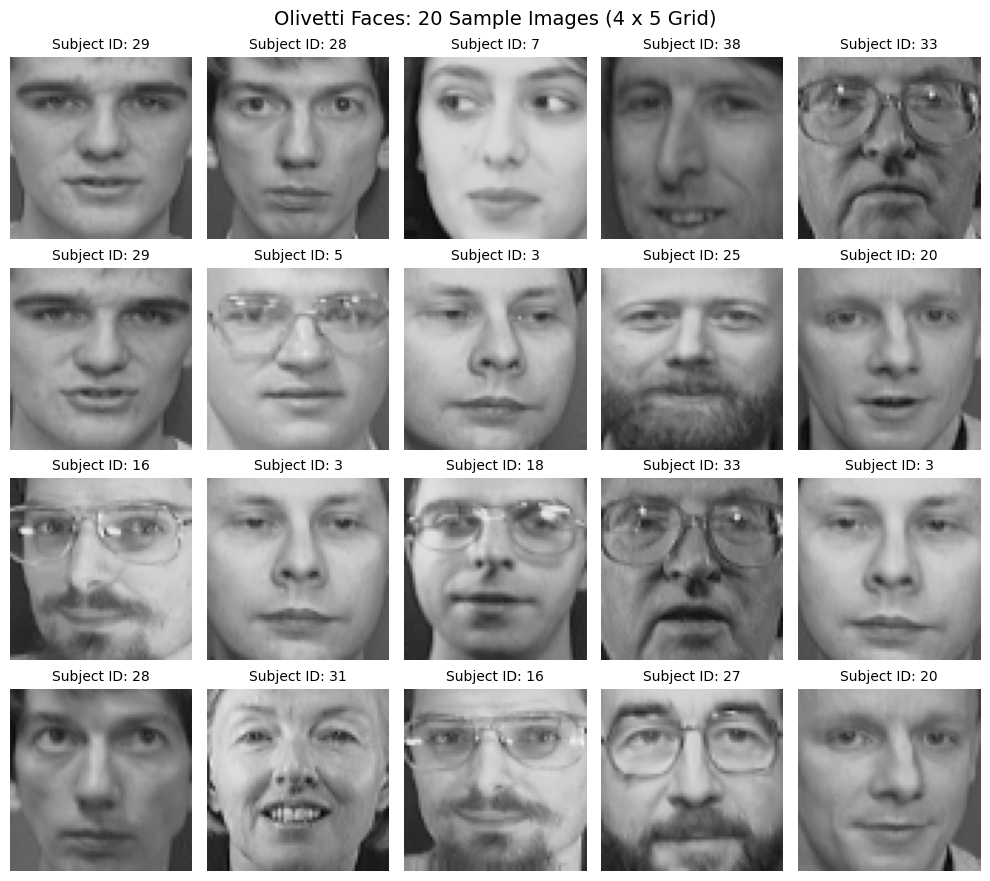

In [ ]:
faces = fetch_olivetti_faces(shuffle=False)

X = faces.data
y = faces.target
images = faces.images

n_samples, n_features = X.shape
n_subjects = len(np.unique(y))

print(f"Total number of samples : {n_samples}")
print(f"Unique target subjects  : {n_subjects}")
print(f"Feature dimensions      : {n_features}  (each image is {images.shape[1]} x {images.shape[2]} = {images.shape[1] * images.shape[2]} pixels)")
print(f"Images per subject      : {np.bincount(y).min()}")
print(f"Pixel intensity range   : [{X.min():.2f}, {X.max():.2f}]")
print(f"Shapes -> data: {X.shape}, target: {y.shape}, images: {images.shape}")

rng = np.random.default_rng(RANDOM_STATE)
sample_idx = rng.choice(n_samples, size=20, replace=False)

fig, axes = plt.subplots(4, 5, figsize=(10, 9))
for ax, idx in zip(axes.ravel(), sample_idx):
    ax.imshow(images[idx], cmap='gray', vmin=0, vmax=1)
    ax.set_title(f"Subject ID: {y[idx]}", fontsize=10)
    ax.axis('off')

fig.suptitle('Olivetti Faces: 20 Sample Images (4 x 5 Grid)', fontsize=14)
plt.tight_layout()
plt.show()

This code cell downloads the Olivetti Faces dataset. It then prints the total number of samples, the number of unique subjects, and the feature dimension.
The second part randomly selects 20 images; drawing them in a 4 x 5 grid of subplots. Each face is displayed in grayscale from its 64 x 64 matrix, and its title shows the subject ID it belongs to.

***Task 2***

Number of principal components computed: 400
Variance explained by PC1 alone          : 0.2381
Variance explained by the first 2 PCs    : 0.3781

Components required to preserve 90% of the variance:  66  (cumulative variance = 0.9002, 62.1x smaller than 4,096 dims)
Components required to preserve 95% of the variance: 123  (cumulative variance = 0.9504, 33.3x smaller than 4,096 dims)
Components required to preserve 99% of the variance: 260  (cumulative variance = 0.9900, 15.8x smaller than 4,096 dims)


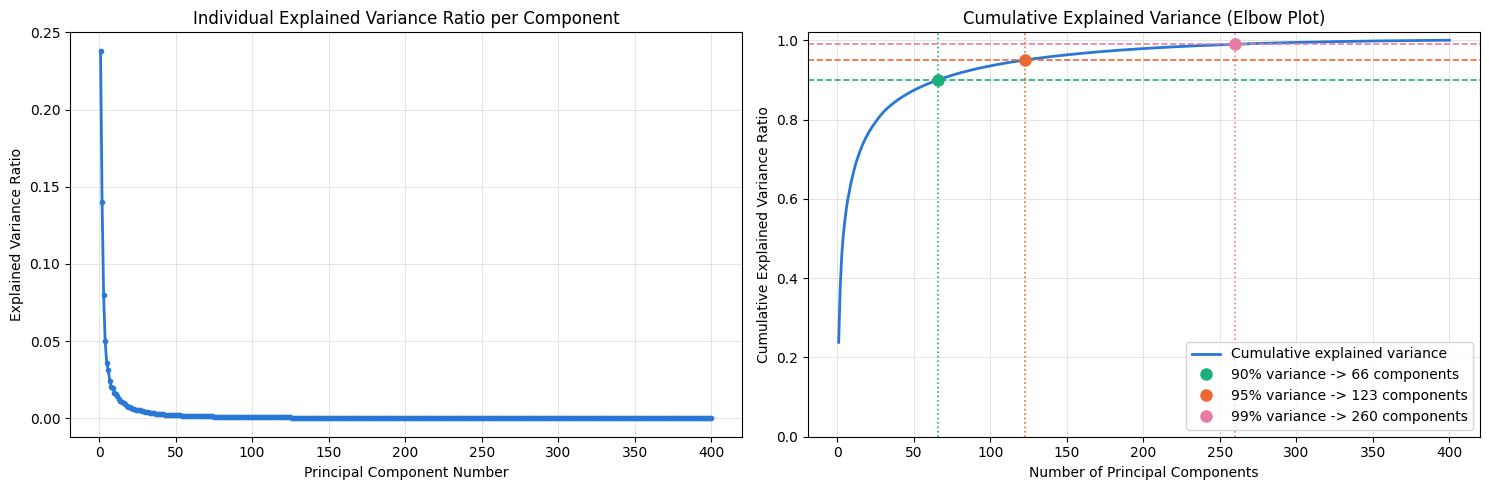

In [ ]:
pca_full = PCA(n_components=None)
pca_full.fit(X)

explained_var = pca_full.explained_variance_ratio_
cumulative_var = np.cumsum(explained_var)

print(f"Number of principal components computed: {len(explained_var)}")
print(f"Variance explained by PC1 alone          : {explained_var[0]:.4f}")
print(f"Variance explained by the first 2 PCs    : {cumulative_var[1]:.4f}\n")

thresholds = [0.90, 0.95, 0.99]
components_needed = {}
for t in thresholds:
    k = int(np.argmax(cumulative_var >= t) + 1)
    components_needed[t] = k
    print(f"Components required to preserve {t:.0%} of the variance: {k:>3}  "
          f"(cumulative variance = {cumulative_var[k - 1]:.4f}, "
          f"{n_features / k:.1f}x smaller than 4,096 dims)")

n_comp = np.arange(1, len(explained_var) + 1)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

ax1.plot(n_comp, explained_var, color=BLUE, linewidth=2, marker='o', markersize=3)
ax1.set_title('Individual Explained Variance Ratio per Component')
ax1.set_xlabel('Principal Component Number')
ax1.set_ylabel('Explained Variance Ratio')
ax1.grid(True, color=GRID, linewidth=0.6)

ax2.plot(n_comp, cumulative_var, color=BLUE, linewidth=2, label='Cumulative explained variance')
for t, color in zip(thresholds, [AQUA, ORANGE, MAGENTA]):
    k = components_needed[t]
    ax2.axhline(t, color=color, linestyle='--', linewidth=1.2)
    ax2.axvline(k, color=color, linestyle=':', linewidth=1.2)
    ax2.plot(k, cumulative_var[k - 1], 'o', color=color, markersize=8,
             label=f'{t:.0%} variance -> {k} components')
ax2.set_title('Cumulative Explained Variance (Elbow Plot)')
ax2.set_xlabel('Number of Principal Components')
ax2.set_ylabel('Cumulative Explained Variance Ratio')
ax2.set_ylim(0, 1.02)
ax2.legend(loc='lower right')
ax2.grid(True, color=GRID, linewidth=0.6)

plt.tight_layout()
plt.show()

This code cell fits a PCA model with no component limit; computing all 400 principal components. For each threshold (90%, 95%, 99%), "np.argmax" finds the first point where the cumulative curve reaches that level. The exact number of components needed is also printed along with how much smaller that representation is than the original. Two side-by-side plots are then created: the left plot shows the explained variance ratio of each individual component and the right plot shows the cumulative explained variance.

***Task 3***

k =  10: compressed shape (5, 10) -> reconstructed shape (5, 4096)
k =  50: compressed shape (5, 50) -> reconstructed shape (5, 4096)
k = 100: compressed shape (5, 100) -> reconstructed shape (5, 4096)
k = 200: compressed shape (5, 200) -> reconstructed shape (5, 4096)
k = 300: compressed shape (5, 300) -> reconstructed shape (5, 4096)

Mean Squared Error between original and reconstructed faces:
                Subject 0  Subject 10  Subject 20  Subject 30  Subject 39  Mean MSE
k (components)                                                                     
10               0.004804    0.006481    0.003622    0.004762    0.004005  0.004735
50               0.002293    0.002595    0.001906    0.001600    0.001893  0.002057
100              0.001208    0.001316    0.001077    0.000841    0.001067  0.001102
200              0.000481    0.000507    0.000467    0.000227    0.000490  0.000435
300              0.000154    0.000090    0.000159    0.000102    0.000207  0.000142


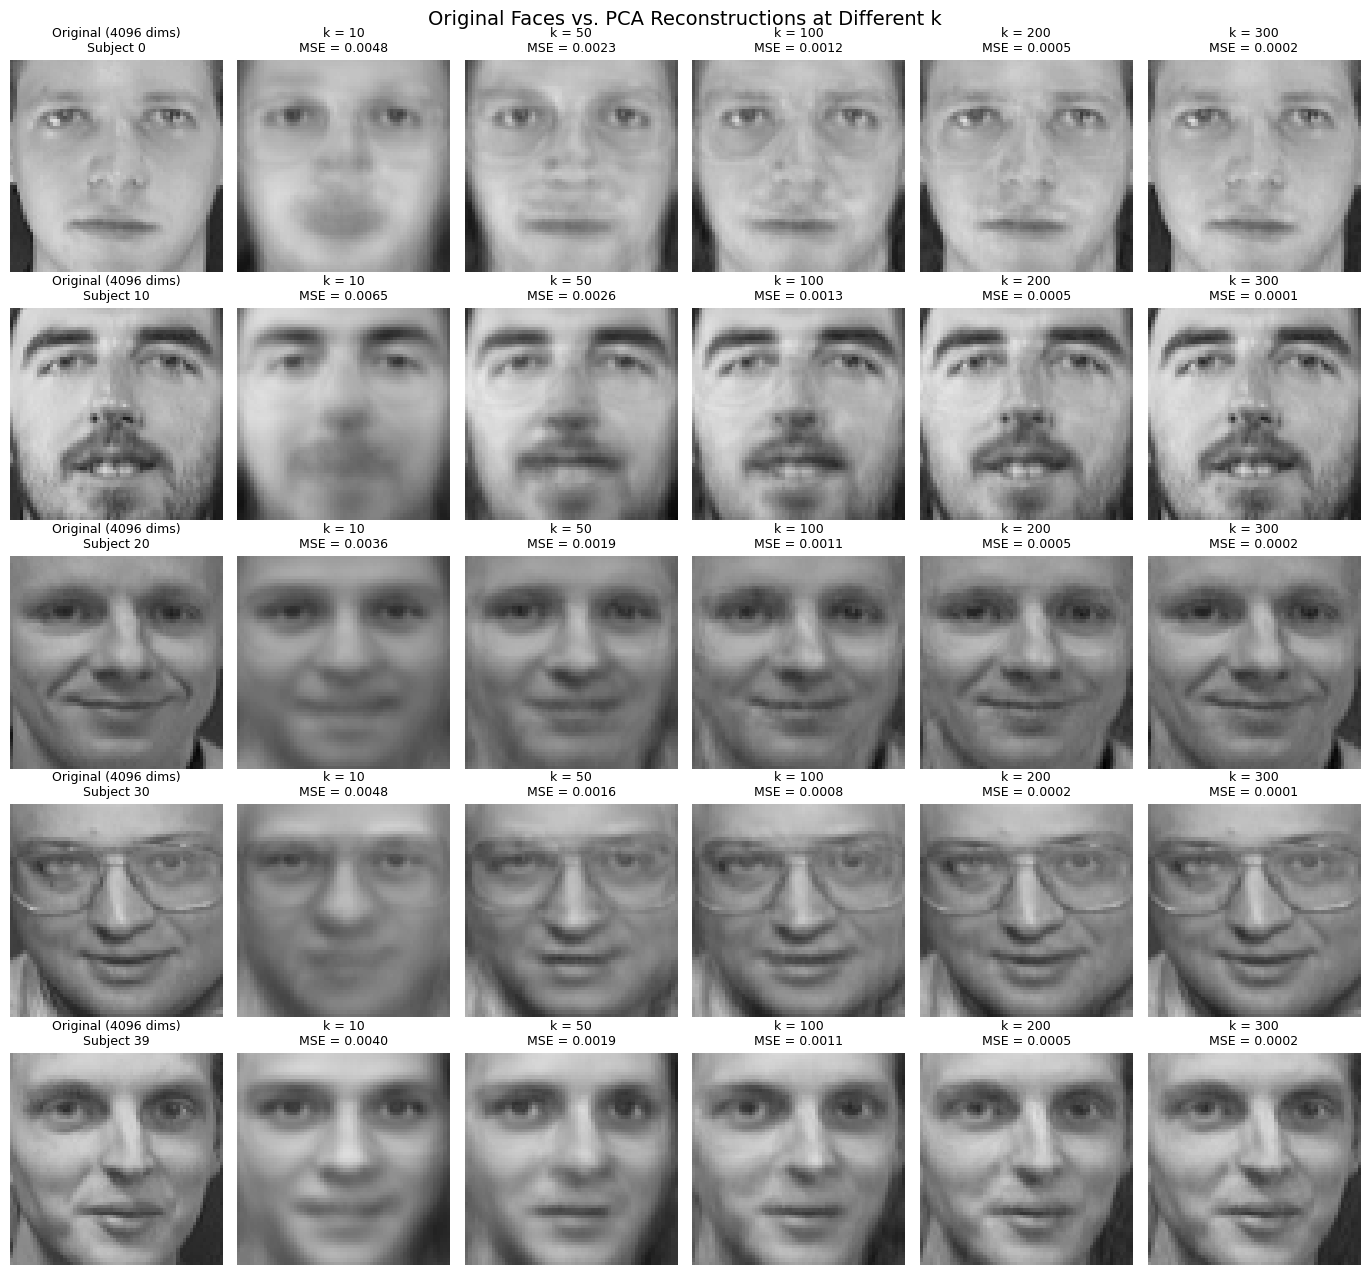

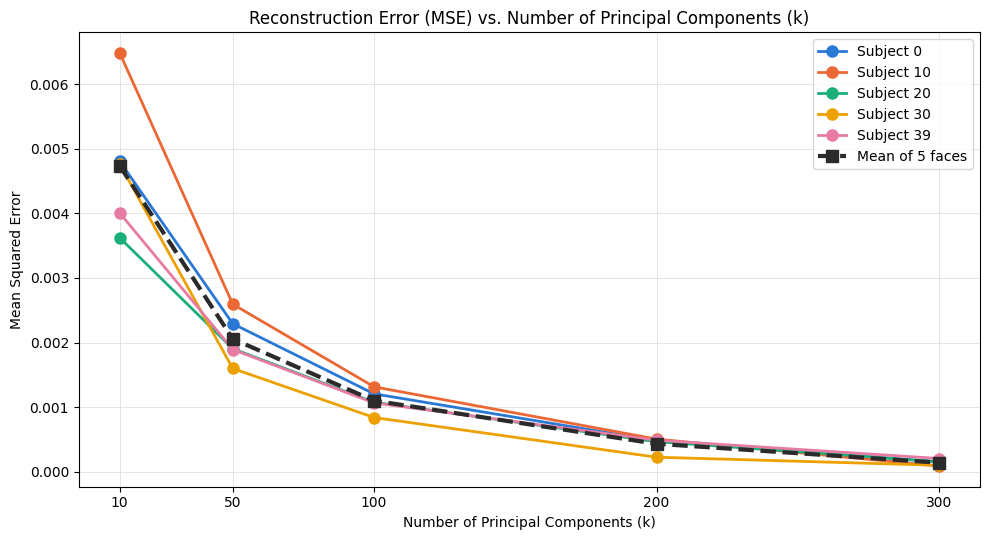

In [ ]:
selected_subjects = [0, 10, 20, 30, 39]
selected_idx = [int(np.where(y == s)[0][0]) for s in selected_subjects]
X_selected = X[selected_idx]

k_values = [10, 50, 100, 200, 300]
reconstructions = {}
mse_per_image = {}

for k in k_values:
    pca_k = PCA(n_components=k)
    pca_k.fit(X)
    X_compressed = pca_k.transform(X_selected)
    X_reconstructed = pca_k.inverse_transform(X_compressed)
    reconstructions[k] = X_reconstructed
    mse_per_image[k] = np.mean((X_selected - X_reconstructed) ** 2, axis=1)
    print(f"k = {k:>3}: compressed shape {X_compressed.shape} -> reconstructed shape {X_reconstructed.shape}")

mse_table = pd.DataFrame(mse_per_image, index=[f'Subject {s}' for s in selected_subjects]).T
mse_table['Mean MSE'] = mse_table.mean(axis=1)
mse_table.index.name = 'k (components)'
print('\nMean Squared Error between original and reconstructed faces:')
print(mse_table.round(6).to_string())

n_rows, n_cols = len(selected_idx), len(k_values) + 1
fig, axes = plt.subplots(n_rows, n_cols, figsize=(2.3 * n_cols, 2.6 * n_rows))

for row, idx in enumerate(selected_idx):
    axes[row, 0].imshow(images[idx], cmap='gray', vmin=0, vmax=1)
    axes[row, 0].set_title(f'Original (4096 dims)\nSubject {y[idx]}', fontsize=9)
    axes[row, 0].axis('off')
    for col, k in enumerate(k_values, start=1):
        rec_img = np.clip(reconstructions[k][row].reshape(64, 64), 0, 1)
        axes[row, col].imshow(rec_img, cmap='gray', vmin=0, vmax=1)
        axes[row, col].set_title(f'k = {k}\nMSE = {mse_per_image[k][row]:.4f}', fontsize=9)
        axes[row, col].axis('off')

fig.suptitle('Original Faces vs. PCA Reconstructions at Different k', fontsize=14)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(10, 5.5))
line_colors = [BLUE, ORANGE, AQUA, YELLOW, MAGENTA]

for (row_label, color) in zip(mse_table.columns[:-1], line_colors):
    ax.plot(k_values, mse_table[row_label], marker='o', markersize=8, linewidth=2,
            color=color, label=row_label)
ax.plot(k_values, mse_table['Mean MSE'], marker='s', markersize=8, linewidth=3,
        color=INK, linestyle='--', label='Mean of 5 faces')

ax.set_xticks(k_values)
ax.set_title('Reconstruction Error (MSE) vs. Number of Principal Components (k)')
ax.set_xlabel('Number of Principal Components (k)')
ax.set_ylabel('Mean Squared Error')
ax.grid(True, color=GRID, linewidth=0.6)
ax.legend()
plt.tight_layout()
plt.show()

This code cell picks five representative faces (one each from subjects 0, 10, 20, 30 and 39). For k = 10, 50, 100, 200 and 300 it compresses them with PCA and rebuilds them, measuring the Mean Squared Error (MSE) between each original and its reconstruction. It is then presented with: a printed MSE table, a 5 × 6 image grid, and a line plot of MSE against k. Together they show faces going from blurry outlines at low k to near-perfect copies at high k, with error falling fastest over the first components.

***Task 4***

Components matrix shape: (400, 4096) -> first 15 reshaped to (15, 64, 64)


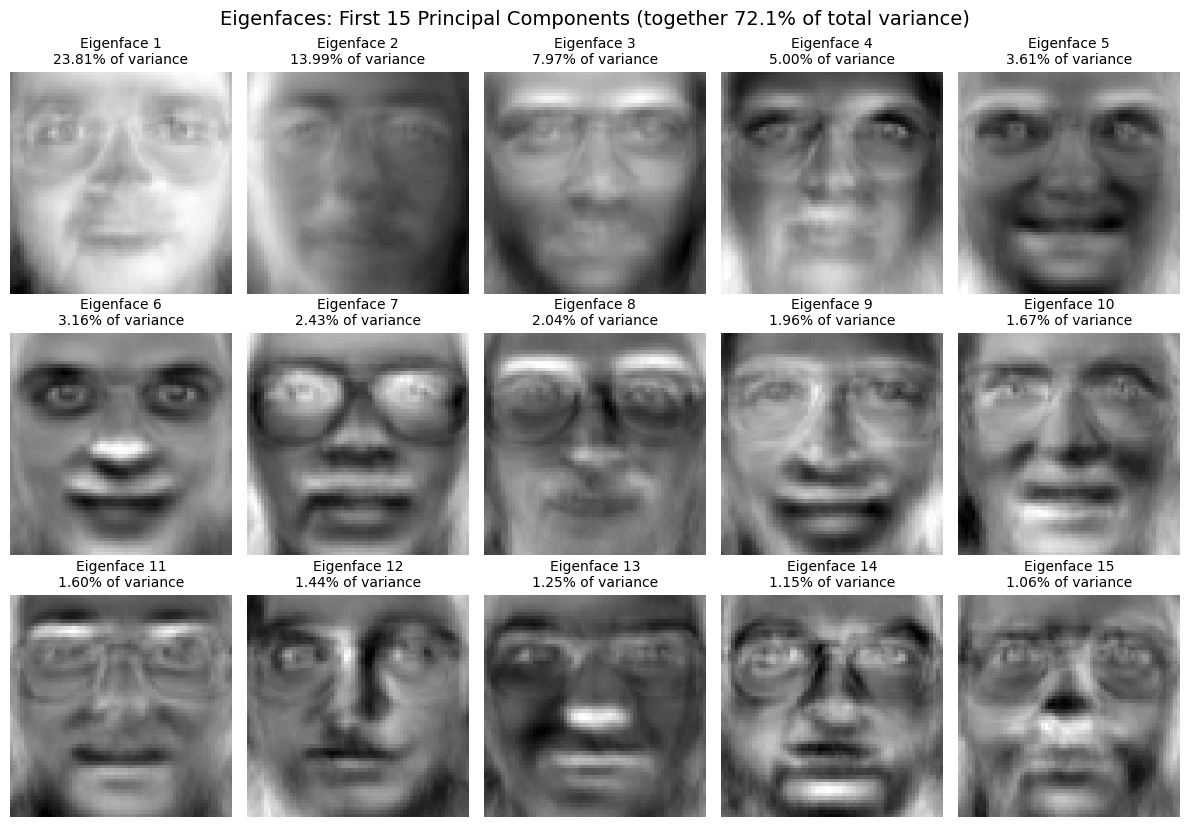

In [ ]:
n_eigen = 15
eigenfaces = pca_full.components_[:n_eigen].reshape(n_eigen, 64, 64)
print(f"Components matrix shape: {pca_full.components_.shape} -> first {n_eigen} reshaped to {eigenfaces.shape}")

fig, axes = plt.subplots(3, 5, figsize=(12, 8.5))
for i, ax in enumerate(axes.ravel()):
    ax.imshow(eigenfaces[i], cmap='gray')
    ax.set_title(f'Eigenface {i + 1}\n{explained_var[i] * 100:.2f}% of variance', fontsize=10)
    ax.axis('off')

fig.suptitle(f'Eigenfaces: First 15 Principal Components '
             f'(together {cumulative_var[n_eigen - 1] * 100:.1f}% of total variance)', fontsize=14)
plt.tight_layout()
plt.show()

This code cell takes the principal components from the PCA fitted in Task 2 and reshapes the first 15 back into 64 × 64 images. It displays them in a 3 × 5 grid. These are the basic patterns PCA combines to rebuild any face: the early ones capture broad lighting and face shape, and later ones capture finer, noisier details.

***Task 5***

Training set: 320 images, Test set: 80 images
Images per subject -> train: 8-8, test: 2-2
PCA (95% variance) fitted on the training set kept 111 components (reduced from 4096).

Logistic Regression (Raw, 4096 dims) -> Test Accuracy: 0.9625 | Training Time: 29.946 s
Logistic Regression (PCA, 111 dims)   -> Test Accuracy: 0.9625 | Training Time: 0.830 s


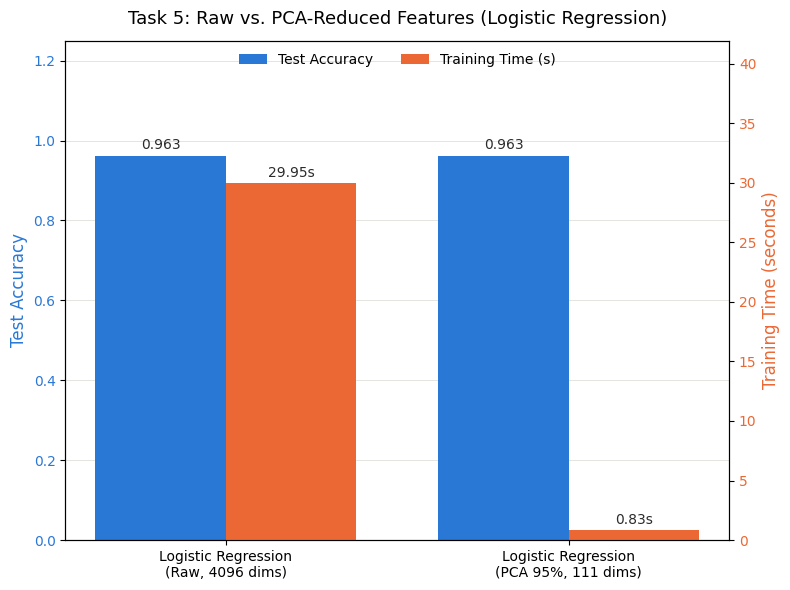

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

print(f"Training set: {X_train.shape[0]} images, Test set: {X_test.shape[0]} images")
print(f"Images per subject -> train: {np.bincount(y_train).min()}-{np.bincount(y_train).max()}, "
      f"test: {np.bincount(y_test).min()}-{np.bincount(y_test).max()}")

logreg_raw = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)

start = time.perf_counter()
logreg_raw.fit(X_train, y_train)
time_lr_raw = time.perf_counter() - start

y_pred_lr_raw = logreg_raw.predict(X_test)
acc_lr_raw = accuracy_score(y_test, y_pred_lr_raw)

logreg_pca = Pipeline([
    ('pca', PCA(n_components=0.95)),
    ('logreg', LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
])

start = time.perf_counter()
logreg_pca.fit(X_train, y_train)
time_lr_pca = time.perf_counter() - start

y_pred_lr_pca = logreg_pca.predict(X_test)
acc_lr_pca = accuracy_score(y_test, y_pred_lr_pca)

n_pca_train = logreg_pca.named_steps['pca'].n_components_
print(f"PCA (95% variance) fitted on the training set kept {n_pca_train} components "
      f"(reduced from {n_features}).\n")
print(f"Logistic Regression (Raw, {n_features} dims) -> Test Accuracy: {acc_lr_raw:.4f} | Training Time: {time_lr_raw:.3f} s")
print(f"Logistic Regression (PCA, {n_pca_train} dims)   -> Test Accuracy: {acc_lr_pca:.4f} | Training Time: {time_lr_pca:.3f} s")

def dual_axis_bar(model_names, accuracies, train_times, title):

    x = np.arange(len(model_names))
    width = 0.38
    fig, ax1 = plt.subplots(figsize=(max(8, 2.6 * len(model_names)), 6))

    bars_acc = ax1.bar(x - width / 2, accuracies, width, color=BLUE, label='Test Accuracy')
    ax1.set_ylabel('Test Accuracy', color=BLUE, fontsize=12)
    ax1.tick_params(axis='y', labelcolor=BLUE)
    ax1.set_ylim(0, 1.25)
    ax1.grid(True, axis='y', color=GRID, linewidth=0.6)
    ax1.set_axisbelow(True)

    ax2 = ax1.twinx()
    bars_time = ax2.bar(x + width / 2, train_times, width, color=ORANGE, label='Training Time (s)')
    ax2.set_ylabel('Training Time (seconds)', color=ORANGE, fontsize=12)
    ax2.tick_params(axis='y', labelcolor=ORANGE)
    ax2.set_ylim(0, max(train_times) * 1.4)


    for bar, acc in zip(bars_acc, accuracies):
        ax1.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.01,
                 f'{acc:.3f}', ha='center', va='bottom', fontsize=10, color=INK)
    for bar, t in zip(bars_time, train_times):
        ax2.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + max(train_times) * 0.01,
                 f'{t:.2f}s', ha='center', va='bottom', fontsize=10, color=INK)

    ax1.set_xticks(x)
    ax1.set_xticklabels(model_names, fontsize=10)
    ax1.legend([bars_acc, bars_time], ['Test Accuracy', 'Training Time (s)'],
               loc='upper center', ncol=2, frameon=False)
    plt.title(title, fontsize=13, pad=12)
    fig.tight_layout()
    plt.show()

dual_axis_bar(
    [f'Logistic Regression\n(Raw, {n_features} dims)', f'Logistic Regression\n(PCA 95%, {n_pca_train} dims)'],
    [acc_lr_raw, acc_lr_pca],
    [time_lr_raw, time_lr_pca],
    'Task 5: Raw vs. PCA-Reduced Features (Logistic Regression)')

This code cell makes a stratified 80/20 split, so each of the 40 subjects has 8 training and 2 test images. It trains two Logistic Regression models: one on the raw 4,096 pixel features, and one inside a pipeline that first reduces the data with 95%-variance PCA fitted only on the training set, preventing data leakage. Each model’s test accuracy and training time is displayed plus the number of components PCA kept. They are then comparied via a reusable dual-axis bar chart.

***Task 6***

SVC (RBF kernel, PCA 111 dims) -> Test Accuracy: 0.9375 | Training Time: 0.295 s
Linear baseline (Logistic Regression, PCA)        -> Test Accuracy: 0.9625 | Training Time: 0.830 s


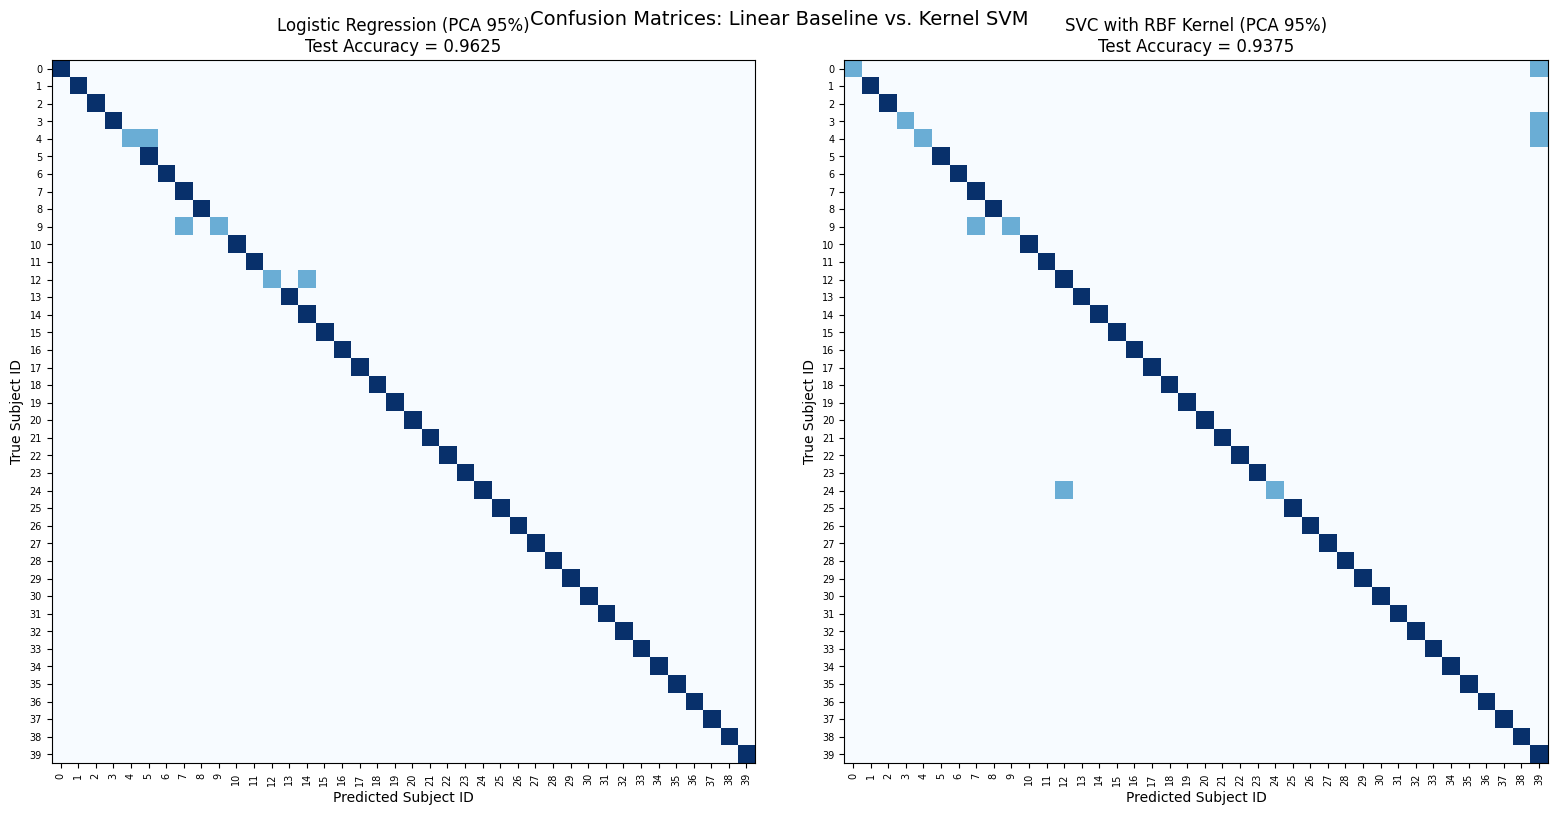

Classification summary on the test set:
                           Accuracy  Macro Precision  Macro Recall  Macro F1-score  Misclassified (of 80)
Logistic Regression (PCA)    0.9625           0.9750        0.9625          0.9600                      3
SVC RBF (PCA)                0.9375           0.9683        0.9375          0.9376                      5

Both correct: 74 | Only Logistic Regression correct: 3 | Only SVC correct: 1 | Both wrong: 2


In [ ]:
svc_rbf_pca = Pipeline([
    ('pca', PCA(n_components=0.95)),
    ('svc', SVC(kernel='rbf', random_state=RANDOM_STATE))
])

start = time.perf_counter()
svc_rbf_pca.fit(X_train, y_train)
time_svc_rbf = time.perf_counter() - start

y_pred_svc_rbf = svc_rbf_pca.predict(X_test)
acc_svc_rbf = accuracy_score(y_test, y_pred_svc_rbf)

print(f"SVC (RBF kernel, PCA {svc_rbf_pca.named_steps['pca'].n_components_} dims) -> "
      f"Test Accuracy: {acc_svc_rbf:.4f} | Training Time: {time_svc_rbf:.3f} s")
print(f"Linear baseline (Logistic Regression, PCA)        -> "
      f"Test Accuracy: {acc_lr_pca:.4f} | Training Time: {time_lr_pca:.3f} s")

fig, axes = plt.subplots(1, 2, figsize=(16, 8))
for ax, y_pred, name, acc in [
        (axes[0], y_pred_lr_pca, 'Logistic Regression (PCA 95%)', acc_lr_pca),
        (axes[1], y_pred_svc_rbf, 'SVC with RBF Kernel (PCA 95%)', acc_svc_rbf)]:
    ConfusionMatrixDisplay.from_predictions(
        y_test, y_pred, ax=ax, cmap='Blues', include_values=False, colorbar=False)
    ax.set_title(f'{name}\nTest Accuracy = {acc:.4f}', fontsize=12)
    ax.set_xlabel('Predicted Subject ID')
    ax.set_ylabel('True Subject ID')
    ax.tick_params(axis='both', labelsize=7)
    ax.tick_params(axis='x', labelrotation=90)
fig.suptitle('Confusion Matrices: Linear Baseline vs. Kernel SVM', fontsize=14)
plt.tight_layout()
plt.show()

rows = {}
for name, y_pred in [('Logistic Regression (PCA)', y_pred_lr_pca), ('SVC RBF (PCA)', y_pred_svc_rbf)]:
    rep = classification_report(y_test, y_pred, output_dict=True, zero_division=0)
    rows[name] = {'Accuracy': rep['accuracy'],
                  'Macro Precision': rep['macro avg']['precision'],
                  'Macro Recall': rep['macro avg']['recall'],
                  'Macro F1-score': rep['macro avg']['f1-score'],
                  'Misclassified (of 80)': int((y_pred != y_test).sum())}
summary_t6 = pd.DataFrame(rows).T
summary_t6['Misclassified (of 80)'] = summary_t6['Misclassified (of 80)'].astype(int)
print('Classification summary on the test set:')
print(summary_t6.round(4).to_string())

both_right = np.sum((y_pred_lr_pca == y_test) & (y_pred_svc_rbf == y_test))
only_lr = np.sum((y_pred_lr_pca == y_test) & (y_pred_svc_rbf != y_test))
only_svc = np.sum((y_pred_lr_pca != y_test) & (y_pred_svc_rbf == y_test))
both_wrong = np.sum((y_pred_lr_pca != y_test) & (y_pred_svc_rbf != y_test))
print(f"\nBoth correct: {both_right} | Only Logistic Regression correct: {only_lr} | "
      f"Only SVC correct: {only_svc} | Both wrong: {both_wrong}")

This code cell trains a SVC with an RBF kernel on the same 95%-variance PCA features. It uses a pipeline so PCA is fitted only on the training data. It compares the SVM against the linear baseline from Task 5 three ways.

***Task 7***

In [ ]:
poly_svm = SVC(kernel='poly', degree=2, probability=True, random_state=RANDOM_STATE)
rbf_svm = SVC(kernel='rbf', probability=True, random_state=RANDOM_STATE)
random_forest = RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE)

voting_clf = VotingClassifier(
    estimators=[('poly_svm', poly_svm), ('rbf_svm', rbf_svm), ('random_forest', random_forest)],
    voting='soft')

ensemble_pca = Pipeline([
    ('pca', PCA(n_components=0.95)),
    ('ensemble', voting_clf)
])

start = time.perf_counter()
ensemble_pca.fit(X_train, y_train)
time_ensemble = time.perf_counter() - start

y_pred_ensemble = ensemble_pca.predict(X_test)
acc_ensemble = accuracy_score(y_test, y_pred_ensemble)
print(f"Soft Voting Ensemble (PCA) -> Test Accuracy: {acc_ensemble:.4f} | Training Time: {time_ensemble:.3f} s")

X_test_pca = ensemble_pca.named_steps['pca'].transform(X_test)
fitted_members = ensemble_pca.named_steps['ensemble'].named_estimators_
member_acc = {name: accuracy_score(y_test, model.predict(X_test_pca))
              for name, model in fitted_members.items()}

comparison_t7 = pd.DataFrame({
    'Model': ['Logistic Regression (PCA) - linear',
              'SVC RBF (PCA) - non-linear',
              'Soft Voting Ensemble (PCA)',
              '   member: Polynomial SVM (degree=2)',
              '   member: RBF SVM',
              '   member: Random Forest (100 trees)'],
    'Test Accuracy': [acc_lr_pca, acc_svc_rbf, acc_ensemble,
                      member_acc['poly_svm'], member_acc['rbf_svm'], member_acc['random_forest']],
    'Training Time (s)': [time_lr_pca, time_svc_rbf, time_ensemble, np.nan, np.nan, np.nan]
}).set_index('Model')
print(comparison_t7.round(4).to_string(na_rep='(part of ensemble)'))

print(f"\nEnsemble vs. Logistic Regression (PCA): {acc_ensemble - acc_lr_pca:+.4f} accuracy, "
      f"{time_ensemble / time_lr_pca:.1f}x the training time")
print(f"Ensemble vs. SVC RBF (PCA)            : {acc_ensemble - acc_svc_rbf:+.4f} accuracy, "
      f"{time_ensemble / time_svc_rbf:.1f}x the training time")

Soft Voting Ensemble (PCA) -> Test Accuracy: 0.9500 | Training Time: 1.171 s
                                      Test Accuracy  Training Time (s)
Model                                                                 
Logistic Regression (PCA) - linear           0.9625             0.8299
SVC RBF (PCA) - non-linear                   0.9375             0.2954
Soft Voting Ensemble (PCA)                   0.9500             1.1714
   member: Polynomial SVM (degree=2)         0.7750 (part of ensemble)
   member: RBF SVM                           0.9375 (part of ensemble)
   member: Random Forest (100 trees)         0.9375 (part of ensemble)

Ensemble vs. Logistic Regression (PCA): -0.0125 accuracy, 1.4x the training time
Ensemble vs. SVC RBF (PCA)            : +0.0125 accuracy, 4.0x the training time


This code cell builds a soft-voting ensemble of three models: a degree-2 polynomial SVM, an RBF SVM and a 100-tree random forest. This averages their predicted probabilities to choose a subject. The ensemble is trained on the 95%-variance PCA features. A comparison table sets it against the single linear and non-linear models, also shows how each ensemble member scores on its own, and prints the accuracy difference and training-time ratio to highlight the trade-off between accuracy and cost.

***Task 8***

                                               Test Accuracy  Training Time (s)
Logistic Regression (Raw Features, 4096 dims)         0.9625            29.9461
Logistic Regression (PCA-Reduced, 111 dims)           0.9625             0.8299
SVC with RBF Kernel (PCA-Reduced, 111 dims)           0.9375             0.2954
Soft Voting Ensemble (PCA-Reduced, 111 dims)          0.9500             1.1714


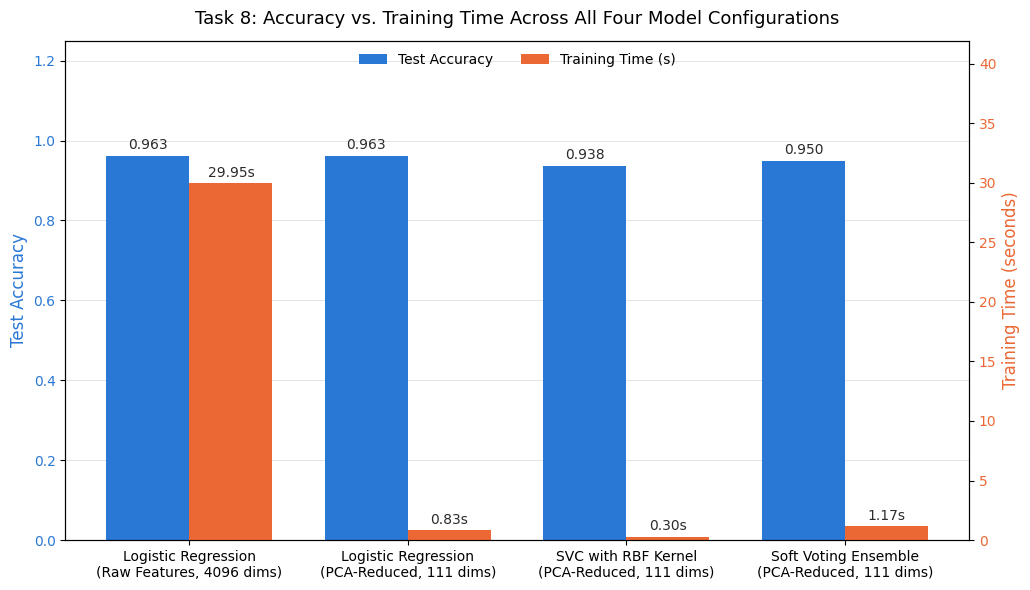

In [ ]:
model_names = [
    f'Logistic Regression\n(Raw Features, {n_features} dims)',
    f'Logistic Regression\n(PCA-Reduced, {n_pca_train} dims)',
    f'SVC with RBF Kernel\n(PCA-Reduced, {n_pca_train} dims)',
    f'Soft Voting Ensemble\n(PCA-Reduced, {n_pca_train} dims)'
]
all_accuracies = [acc_lr_raw, acc_lr_pca, acc_svc_rbf, acc_ensemble]
all_times = [time_lr_raw, time_lr_pca, time_svc_rbf, time_ensemble]

summary = pd.DataFrame({'Test Accuracy': all_accuracies, 'Training Time (s)': all_times},
                       index=[m.replace('\n', ' ') for m in model_names])
print(summary.round(4).to_string())

dual_axis_bar(model_names, all_accuracies, all_times,
              'Task 8: Accuracy vs. Training Time Across All Four Model Configurations')

This code cell gathers the measured accuracy and training time of all four models: logistic regression on raw features, logistic regression on PCA features, the RBF SVM on PCA features and the soft-voting ensemble on PCA features. It prints them in one summary table and draws a single bar chart.